In [1]:
# Copyright (c) Meta Platforms, Inc. and affiliates.
# All rights reserved.
#
# This source code is licensed under the license found in the
# LICENSE file in the root directory of this source tree.
#

from typing import Tuple
from enum import Enum
from dataclasses import dataclass

import colorama
import datetime
import random
import sys
import torch
import traceback
import transformers
import os

from arguments import Arguments, simple_parse_args_string
from self_speculation.autoregressive_generator import AutoRegressiveGenerationStrategy
from self_speculation.generator_base import (
    GenerationConfig,
    GenerationResult,
    GenerationStrategy,
    HuggingfaceLlamaGenerator,
)
from self_speculation.self_speculation_generator import SelfSpeculativeGenerationStrategy
from self_speculation.speculative_streamer import SpeculativeTextStreamer


/home/llminfliu/anaconda3/envs/layer_skip/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import os
import torch.distributed as dist

# Set variables manually inside python
os.environ['MASTER_ADDR'] = 'localhost'
os.environ['MASTER_PORT'] = '29500'
os.environ['LOCAL_RANK'] = '0'
os.environ['RANK'] = '0'
os.environ['WORLD_SIZE'] = '1'


In [3]:
class StreamerType(str, Enum):
    NONE="none"
    STANDARD="standard"
    SPECULATIVE="speculative"

@dataclass
class GenerateArguments:
    streamer: StreamerType = StreamerType.STANDARD

def load_model_and_tokenizer(args: Arguments, device: str = "auto"):
    local_model_path: str = args.model

    # initialize model
    tokenizer = transformers.AutoTokenizer.from_pretrained(local_model_path)
    model = transformers.AutoModelForCausalLM.from_pretrained(
        local_model_path,
        use_safetensors=True,
        device_map="auto",
        torch_dtype=torch.float16,
    )
    model.eval()

    return model, tokenizer

def process_cli_arguments(model_args) -> Tuple[Arguments, GenerateArguments, GenerationConfig]:
    parser = transformers.HfArgumentParser((Arguments, GenerateArguments, GenerationConfig))
    (
        general_arguments,
        generate_arguments,
        generation_config,
    ) = parser.parse_args_into_dataclasses(args=model_args,return_remaining_strings=False)

    if general_arguments.model_args:
        general_arguments.model_args = simple_parse_args_string(general_arguments.model_args)
    else:
        general_arguments.model_args = {}

    return general_arguments, generate_arguments, generation_config

In [4]:
#model_arg_list = ['--model', 'facebook/layerskip-llama3.2-1B', '--sample', 'True', '--max_steps', '512']
model_arg_list = ['--model', 'facebook/layerskip-llama2-7B', '--sample', 'True', '--max_steps', '512']
#model_arg_list = ['--model', 'facebook/layerskip-llama3.2-1B', '--sample', 'True', '--max_steps', '512']


args, generate_arguments, generation_config = process_cli_arguments(model_arg_list)

#device = "cuda" if torch.cuda.is_available() else "cpu"
#backend_str = "cpu:gloo" if "cpu" in device else "cuda:nccl,cpu:gloo"
device = "cpu"
backend_str = "cpu:gloo"


# Setup
torch.distributed.init_process_group(
    backend=backend_str,
    timeout=datetime.timedelta(hours=48)
)
rank = int(os.environ["LOCAL_RANK"])

random.seed(args.seed)
torch.manual_seed(args.seed)

transformers.utils.logging.set_verbosity_error()
model, tokenizer = load_model_and_tokenizer(args, device=device)

streamer = None
match generate_arguments.streamer:
    case StreamerType.NONE:
        streamer = None
    case StreamerType.STANDARD:
        streamer = transformers.TextStreamer(tokenizer)
    case StreamerType.SPECULATIVE:
        streamer = SpeculativeTextStreamer(tokenizer)
    case _:
        raise ValueError(f"Unsupported streamer type {generate_arguments.streamer}")

if generation_config.generation_strategy == "autoregressive":
    generation_strategy: GenerationStrategy = AutoRegressiveGenerationStrategy()
elif generation_config.generation_strategy == "self_speculative":
    generation_strategy: GenerationStrategy = SelfSpeculativeGenerationStrategy()
else:
    raise Exception(
        f"Unsupported generation strategy: {generation_config.generation_strategy}"
    )

# initialize generator
generator = HuggingfaceLlamaGenerator(
    tokenizer=tokenizer, model=model, generation_strategy=generation_strategy
)

Loading checkpoint shards: 100%|██████████| 3/3 [01:15<00:00, 25.10s/it]


In [5]:
model

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(32000, 4096)
    (layers): ModuleList(
      (0-31): 32 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=4096, out_features=4096, bias=False)
          (k_proj): Linear(in_features=4096, out_features=4096, bias=False)
          (v_proj): Linear(in_features=4096, out_features=4096, bias=False)
          (o_proj): Linear(in_features=4096, out_features=4096, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=4096, out_features=11008, bias=False)
          (up_proj): Linear(in_features=4096, out_features=11008, bias=False)
          (down_proj): Linear(in_features=11008, out_features=4096, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): LlamaRMSNorm((4096,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((4096,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((4096,), eps=1e-05)
    (rotary_e

In [6]:
from torchview import draw_graph

In [7]:
inputs = tokenizer("This is a warmup prompt", return_tensors="pt")

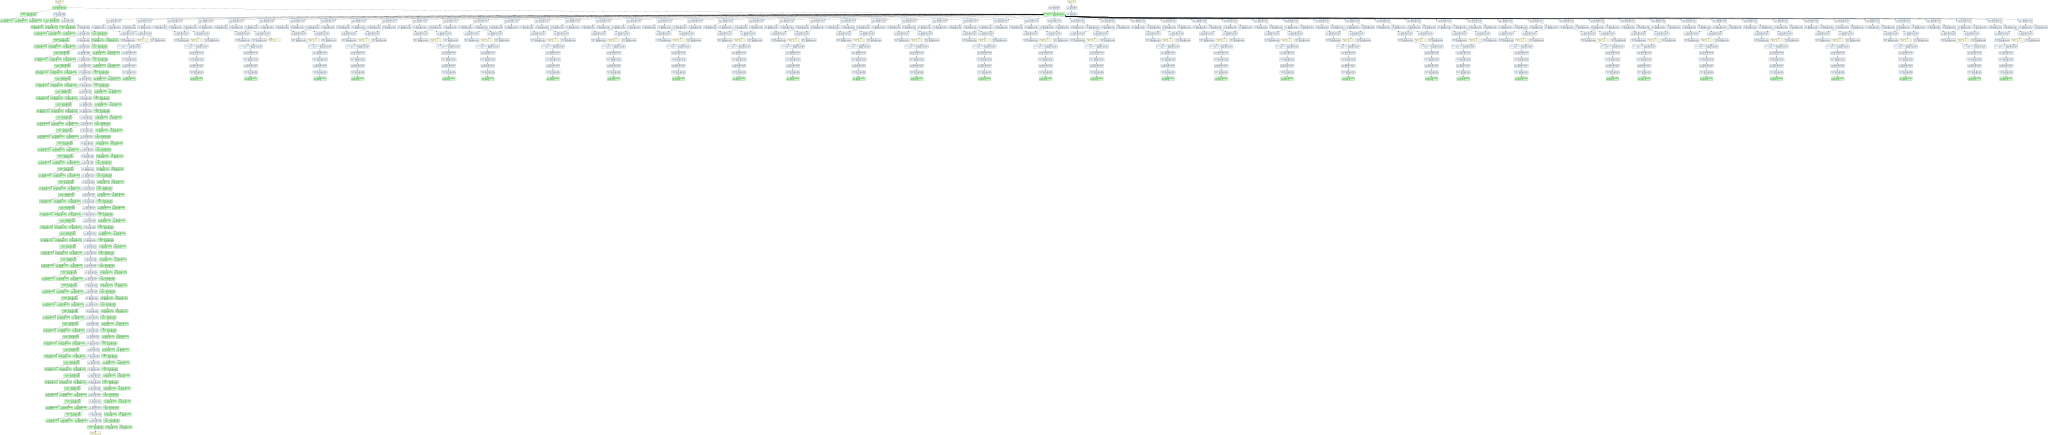

In [8]:
model_graph = draw_graph(model.model, input_data=inputs, expand_nested=False).visual_graph
model_graph

In [ ]:
# Warmup
warmup = 1
for _ in range(warmup):
    model.generation_config.pad_token_id = tokenizer.eos_token_id
    model.generate(**tokenizer("This is a warmup prompt", return_tensors="pt").to(device), max_new_tokens=10)

In [ ]:
while True:
    print()
    print("Enter a prompt and then press ctrl+d twice for the model to complete:")
    print("======================================================================")
    print()

    print(colorama.Fore.LIGHTBLUE_EX, end="")
    prompt=sys.stdin.read()
    print(colorama.Style.RESET_ALL, end=" ")

    try:
        response: GenerationResult = generator.generate(
            prompt=prompt,
            generation_config=generation_config,
            streamer=streamer,
        )
    except:
        print(colorama.Style.RESET_ALL)
        traceback.print_exc()
        raise
    num_tokens = response.num_tokens_generated
    total_time = response.total_time

    if streamer:
        streamer.end()
    else:
        print(response.decoded_prediction)

    print(colorama.Style.RESET_ALL)
    print()
    print(f"\tTime taken: {total_time :.3f}s")
    print(f"\tNumber of tokens: {num_tokens}")
    print(f"\tTime per token: {total_time / num_tokens : .3f}s")
    print(f"\tTokens per second: {num_tokens / total_time :.3f}")
    if generation_config.generation_strategy == "self_speculative":
        print(f"\tAcceptance Rate: {response.generation_strategy_result.acceptance_rate:.2%}")
    print()

